# Thermo-Optic Phase Shifters in Silicon -- Heat Flow, Mode Overlap, $P_\pi$, Speed and Crosstalk

A **thermo-optic phase shifter** is a resistive heater placed next to a silicon waveguide:
the heat raises the waveguide's temperature, silicon's refractive index rises with it, and
the light picks up extra phase. It is the most common tuning element in silicon photonics:
it trims the phase of Mach-Zehnder interferometers, aligns ring resonators and filters to
the laser grid, and switches light in programmable meshes. Every co-packaged-optics
transmitter built from rings needs one heater per ring.

This notebook builds the heater from its physics and judges it against the literature:

1. **Theory** (section 1): why $P_\pi$ does not depend on the heater length, how the mode
   overlap and the group index enter the phase, and what sets the speed.
2. **Optical mode** of a real 220 nm silicon strip at $\lambda_0 = 1.31\ \mu$m, solved with
   MPB (sections 2-4).
3. **Heat flow** through the real cross-section, solved with a 2D finite-volume solver and
   validated against an exact solution (section 5).
4. **Benchmark** against Jacques et al., *Opt. Express* 27, 10456 (2019): $P_\pi$, time
   constant and heater-induced loss of a TiN and an N++ heater (section 6).
5. **Design at 1.31 µm**: TiN width, deep trenches, N++ heater distance, thermal crosstalk,
   frequency response and ring tuning (sections 7-12).
6. A **design point**, a **SAX model** and **GDS layouts** (section 13).

**This notebook deviates from the toolkit's shared modeling convention** (2D top view,
effective core index 2.7): heaters act through the real cross-section, so the optical mode
is solved in the **real cross-section with bulk indices** (Si from Frey et al. 2006,
SiO$_2$ from Malitson 1965), each held constant at $\lambda_0$ (non-dispersive), and the
heat flow is solved in the same cross-section. Sources and their tiers are in
[`../literature.md`](../literature.md).

**Kernel:** the `mp` conda env (MPB for the mode; numpy/scipy for the heat). There is no FDTD
here: the whole notebook runs in about 10 minutes. **Do not use "Run All."** Run the
sections in order and read the checkpoints.

## 1. Physical objective

### 1.1 The thermo-optic effect

Silicon's refractive index rises with temperature. At room temperature (295 K) Frey et al.
measured

| $\lambda$ | 1.3 µm | 1.4 µm | 1.5 µm |
|---|---|---|---|
| $dn_\mathrm{Si}/dT$ (K$^{-1}$) | $1.94\times10^{-4}$ | $1.90\times10^{-4}$ | $1.87\times10^{-4}$ |

which gives $1.936\times10^{-4}$ K$^{-1}$ at 1.31 µm. Silica's coefficient is about 20 times
smaller ($\approx1\times10^{-5}$ K$^{-1}$), so practically all the phase comes from the
silicon core. A 25 K rise in a 100 µm long waveguide gives
$\Delta\phi = 2\pi L\,\Delta n/\lambda \approx 2\pi\cdot100\cdot(1.94\times10^{-4}\cdot25)/1.31 \approx 2.3$ rad.

### 1.2 Why $P_\pi$ does not depend on the heater length

Heat conduction is linear: in a cross-section that is the same along the whole heater, the
temperature rise at every point is proportional to the power dissipated **per unit length**,
$P' = P/L$. Write the resulting change of the mode's effective index as
$\Delta n_\mathrm{eff} = s\,P/L$, with $s$ (m/W) a property of the cross-section alone. The
phase over the heater is then

$$
\Delta\phi = \frac{2\pi}{\lambda}\,\Delta n_\mathrm{eff}\,L = \frac{2\pi}{\lambda}\,s\,P ,
\qquad P_\pi = \frac{\lambda}{2s}.
$$

The length cancels. A longer heater spreads the same power over more waveguide: each micron
gets less heat, but there are more microns. Length still matters for the heater's
**resistance** (the drive voltage) and for its current density, not for $P_\pi$. This
holds as long as the heater is much longer than the cross-section (tens of µm against a few
µm), which is the condition for a 2D cross-section model.

### 1.3 Mode overlap and the group index

The temperature is not uniform over the mode, so $\Delta n_\mathrm{eff}$ is a weighted
average. First-order perturbation theory at **fixed frequency** gives

$$
\Delta n_\mathrm{eff} = n_g\,\frac{\int n\,\Delta n\,|\mathbf{E}|^2\,dA}{\int \varepsilon\,|\mathbf{E}|^2\,dA},
\qquad \Delta n(x,y) = \frac{dn}{dT}\,\Delta T(x,y).
$$

MPB's perturbation formula gives the frequency shift at fixed $k$,
$\Delta\omega/\omega = -\tfrac12\langle\Delta\varepsilon\rangle/\langle\varepsilon\rangle$
with $\Delta\varepsilon = 2n\,\Delta n$; converting to fixed $\omega$ with the group
velocity, $\Delta k = -\Delta\omega/v_g$, brings in the **group index** $n_g$, not $n_\mathrm{eff}$.
For a uniform heat-up of the core alone, $\Delta n_\mathrm{eff}\approx (n_g/n_\mathrm{Si})\,
\Gamma_\mathrm{Si}\,\Delta n_\mathrm{Si}$, where $\Gamma_\mathrm{Si}$ is the fraction of the
electric energy in the silicon. In a high-contrast strip, $n_g/n_\mathrm{Si} > 1$: the
waveguide's dispersion **amplifies** the index change. A model that multiplies the core
temperature by $dn_\mathrm{Si}/dT$ (the "point" metric used in many heater papers) misses
this factor; section 7 quantifies it.

### 1.4 Speed

The heater and the oxide around it store heat (heat capacity per length $C'$) and lose it to
the substrate through a thermal resistance ($R'$). The response to a power step is close to
$1-e^{-t/\tau}$ with $\tau\approx R'C'$, set mostly by how far the heat must travel through
oxide ($D_\mathrm{SiO_2}=k/\rho c_p\approx 0.9\ \mu$m$^2$/µs, so 2 µm of oxide takes a few
µs). Insulating the waveguide (trenches, undercut) raises $R'$: $P_\pi$ falls but $\tau$
rises. The product $P_\pi\tau$ is therefore a common figure of merit (Harris et al. 2014).

### 1.5 What changes what

| If you change... | ...this happens | Why |
|---|---|---|
| Heater length $L$ | $P_\pi$ unchanged; resistance and $\phi_0$ grow | heat per length falls as $1/L$ (1.2) |
| Heater closer to the core (oxide gap) | lower $P_\pi$, faster | less oxide between heater and core; but metal absorbs light if too close |
| N++ heater closer to the rib | lower $P_\pi$, faster | heat enters the slab next to the core; free-carrier absorption rises exponentially |
| Deep trenches beside the heater | much lower $P_\pi$, slower, less crosstalk | heat cannot escape sideways through the oxide |
| Wavelength $\lambda$ | $P_\pi\propto\lambda$ (at fixed $s$) | $\Delta\phi = 2\pi s P/\lambda$ |
| Waveguide confinement ($n_g$, $\Gamma_\mathrm{Si}$) | stronger, high-$n_g$ strip -> lower $P_\pi$ | 1.3 |

In [1]:
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from pic_toolkit.active import thermal as th, si_xsection as xs, thermo_optic as to
from pic_toolkit import design_points, style

style.apply_style()  # shared color palette + plot style for every notebook in this toolkit
%matplotlib inline

# ============================================================
# USER PARAMETERS
# ============================================================
WL0 = 1.31                    # um, O-band design wavelength
WG_WIDTH = 0.40               # um, Si strip width (single-mode check in section 3)
DNDT_SI = xs.si_dndT(WL0)     # 1/K, Frey 2006 Table 4 interpolated
STACK = dict(th.DEFAULT_STACK)  # 220 nm Si, 90 nm slab, 2 um BOX, top oxide to 2.5 um, 6 um substrate in the model
DATA = Path("../data"); (DATA / "design_points").mkdir(parents=True, exist_ok=True); (DATA / "gds").mkdir(exist_ok=True)

mat = xs.materials({**xs.DEFAULT_PARAMS, "wl0_um": WL0})
print(f"wl0 = {WL0} um:  n_Si = {mat['n_si']:.4f} (Frey 2006),  n_SiO2 = {mat['n_ox']:.4f} (Malitson 1965)")
print(f"dn/dT: Si {DNDT_SI:.3e} 1/K (Frey 2006),  SiO2 {xs.SIO2_DNDT:.1e} 1/K (Jacques 2019)")
print("thermal stack:", STACK)

wl0 = 1.31 um:  n_Si = 3.5049 (Frey 2006),  n_SiO2 = 1.4468 (Malitson 1965)
dn/dT: Si 1.936e-04 1/K (Frey 2006),  SiO2 1.0e-05 1/K (Jacques 2019)
thermal stack: {'si_um': 0.22, 'slab_um': 0.09, 'box_um': 2.0, 'clad_top_um': 2.5, 'substrate_um': 6.0, 'half_width_um': 20.0, 'h_conv': 10.0}


## 2. Platform and materials

The stack is the standard 220 nm silicon-on-insulator of the commercial foundries and the one
Jacques et al. used, so the benchmark of section 6 and the design of sections 7-12 share it:

| Layer | Thickness / position | Thermal conductivity (W/(m·K)) | Source |
|---|---|---|---|
| Si substrate | below the BOX (6 µm kept in the model, isothermal bottom) | 148 | Jacques 2019 Table 3 |
| Buried oxide | 2 µm | 1.38 | same |
| Si strip (220 nm) / slab (90 nm) | $y = 0$ to 0.22 / 0.09 µm | 90 / 55 (thin-film values) | same |
| N++ Si (heater) | in the slab | 25 | same |
| Top oxide | to $y = 2.5$ µm, convection 10 W/(m²K) to air above | 1.38 | same |
| TiN heater | 200 nm thick, bottom 2 µm above the Si top | 28 | same |

Heat capacities: Si 2330 kg/m³ × 711 J/(kg·K), SiO$_2$ 2203 × 709, TiN 5240 × 598. The
reduced conductivity of the thin silicon layers comes from phonon scattering at their
surfaces. Every value is from Jacques Table 3 (read through Flexcompute's reproduction of the
paper; see `../literature.md`).

**Coordinates** in every figure: $x$ lateral, $y$ vertical with $y=0$ at the top of the BOX.

## 3. Optical mode at 1.31 µm

### 3.1 Single-mode width

A heater is used in interferometers and rings, which need a single-mode waveguide. The
strip width is chosen as the widest that guides only the fundamental TE mode at 1.31 µm.

In [2]:
# Guided TE bands (n_eff above the oxide index) for a few widths. Each MPB solve takes ~10 s.
for w in (0.38, 0.40, 0.45, 0.50):
    bands = xs.guided_te_bands({"wl0_um": WL0, "wg_width_um": w})
    print(f"width {w:.2f} um: guided TE n_eff = {[round(b, 4) for b in bands]}")

width 0.38 um: guided TE n_eff = [2.5121]


width 0.40 um: guided TE n_eff = [2.5594]


width 0.45 um: guided TE n_eff = [2.6497, 1.4989]


width 0.50 um: guided TE n_eff = [2.7129, 1.5812]


At 0.45 µm a second TE mode is (weakly) guided, so the strip is set to **0.40 µm**, close to
the widths O-band foundry libraries use for single-mode strips.

### 3.2 The mode and its resolution convergence

resolution  32 px/um: n_eff = 2.54951, n_g = 4.1260


resolution  48 px/um: n_eff = 2.56452, n_g = 4.1506


resolution  64 px/um: n_eff = 2.55936, n_g = 4.1431


resolution  96 px/um: n_eff = 2.56134, n_g = 4.1468



production: n_eff = 2.5594, n_g (waveguide dispersion) = 4.1431, n_g (incl. material dispersion) = 4.3302, TE fraction = 0.742


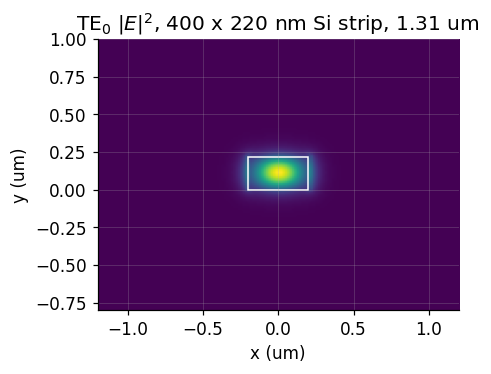

In [3]:
# Fundamental TE mode of the 400 x 220 nm strip, and n_eff / n_g against MPB resolution.
P_STRIP = {"wl0_um": WL0, "wg_width_um": WG_WIDTH}
for r in (32, 48, 64, 96):
    m = xs.solve_mode(P_STRIP, resolution=r)
    print(f"resolution {r:3d} px/um: n_eff = {m.n_eff:.5f}, n_g = {m.n_g:.4f}")
strip = xs.solve_mode(P_STRIP)              # production resolution 64
ng_disp = xs.group_index_material_dispersive(P_STRIP)
print(f"\nproduction: n_eff = {strip.n_eff:.4f}, n_g (waveguide dispersion) = {strip.n_g:.4f}, "
      f"n_g (incl. material dispersion) = {ng_disp:.4f}, TE fraction = {strip.te_fraction:.3f}")

fig, ax = plt.subplots(figsize=(6, 3.2))
ext = [strip.x_um[0], strip.x_um[-1], strip.y_um[0], strip.y_um[-1]]
ax.imshow(strip.E2 / strip.E2.max(), origin="lower", extent=ext, cmap=style.CMAP_DENSITY, aspect="equal")
ax.add_patch(Rectangle((-WG_WIDTH / 2, 0), WG_WIDTH, 0.22, fill=False, ec="white", lw=1))
ax.set_xlim(-1.2, 1.2); ax.set_ylim(-0.8, 1.0)
ax.set_xlabel("x (um)"); ax.set_ylabel("y (um)"); ax.set_title(r"TE$_0$ $|E|^2$, 400 x 220 nm Si strip, 1.31 um")
plt.show()

$n_\mathrm{eff}$ moves by about $\pm0.01$ between resolutions because the 220 nm height
falls between grid lines differently at each resolution; between 64 and 96 px/µm it changes
by under 0.1 %. The thermo-optic quantities below are **ratios** of overlap integrals, which
are less sensitive than $n_\mathrm{eff}$ itself; 64 px/µm is used throughout. The group index
from MPB holds the material indices constant (waveguide dispersion only); with silicon's and
silica's own dispersion included it rises from 4.14 to 4.33. The first one belongs in the
perturbation formula of section 1.3, which is evaluated in the same non-dispersive model; the
second one sets the FSR and the resonance shift of a real ring (section 12).

## 4. Checking the perturbation formula

Before trusting the overlap formula of section 1.3 with a non-uniform temperature, test it
on a case MPB can solve exactly: heat **everything** uniformly by 10 K, which changes the Si
and SiO$_2$ indices everywhere, and solve the mode again.

In [4]:
# Uniform 10 K: perturbation formula vs a direct MPB solve with the heated indices.
dT = 10.0
d_si, d_ox = DNDT_SI * dT, xs.SIO2_DNDT * dT
pert = xs.perturbation_dneff(strip, np.full(strip.E2.shape, d_si), np.full(strip.E2.shape, d_ox))
direct = xs.solve_mode(P_STRIP, n_si=strip.n_si + d_si, n_ox=strip.n_ox + d_ox).n_eff - strip.n_eff
print(f"Delta n_eff: perturbation {pert['dneff']:.4e}, direct MPB {direct:.4e}, "
      f"difference {100 * (pert['dneff'] / direct - 1):+.2f} %")
print(f"Si share of the change: {100 * pert['si_share']:.1f} %;  electric energy in Si: {100 * pert['confinement_si']:.1f} %")
print(f"(n_g / n_Si) * Gamma_Si = {strip.n_g / strip.n_si * pert['confinement_si']:.3f}  (enhancement over dn_Si/dT * dT)")

Delta n_eff: perturbation 2.1522e-03, direct MPB 2.1447e-03, difference +0.35 %
Si share of the change: 99.1 %;  electric energy in Si: 93.2 %
(n_g / n_Si) * Gamma_Si = 1.102  (enhancement over dn_Si/dT * dT)


The formula agrees with the direct solve to a few tenths of a percent. Silicon carries about
99 % of the index change. The factor $(n_g/n_\mathrm{Si})\,\Gamma_\mathrm{Si}\approx1.10$ is the
enhancement of section 1.3: the mode's index changes about 10 % more than the bulk silicon
index does.

## 5. Validating the heat solver

`pic_toolkit/active/thermal.py` solves the steady and transient heat equation on a
non-uniform grid (20 nm cells around the waveguide and heater, growing to 0.5 µm far away),
with the substrate bottom held at ambient temperature, convection at the top surface and
adiabatic sides.

**Exact test.** A heater sheet that spans the whole width, with no convection, sends all
its heat straight down through the layers. The temperature at every height is then known
exactly: $\Delta T(y) = (P'/W)\sum_i t_i/k_i$ over the layers between the sink and $y$.

In [5]:
# Full-width sheet heater: FV solution vs the exact 1D series-resistance result, plus the energy balance.
p_sheet = th.layered_sheet_heater(STACK)
T_sheet = th.solve_steady(p_sheet, 1.0)
it = th.interpolator(p_sheet, T_sheet)
exact = th.layered_sheet_exact(STACK)
for name, y in (("BOX top", 0.0), ("heater bottom", 2.22), ("heater top", 2.42)):
    key = {"BOX top": "T_box_top", "heater bottom": "T_heater_bottom", "heater top": "T_heater_top"}[name]
    print(f"{name:14s}: FV {it([[y, 0.0]])[0]:.6e} K   exact {exact[key]:.6e} K   (per W/m)")
print("energy balance, sheet:", {k: round(v, 12) for k, v in th.heat_balance(p_sheet, T_sheet, 1.0).items()})

p_tin_bench = th.tin_heater_strip(wg_width_um=0.5, stack=STACK)
T = th.solve_steady(p_tin_bench, 1.0)
bal = th.heat_balance(p_tin_bench, T, 1.0)
print(f"energy balance, TiN heater: {100 * bal['p_bottom']:.3f} % to the substrate, {100 * bal['p_top']:.3f} % "
      f"by convection, error {bal['rel_error']:.1e}")

BOX top       : FV 3.724540e-02 K   exact 3.724540e-02 K   (per W/m)
heater bottom : FV 7.746279e-02 K   exact 7.746279e-02 K   (per W/m)
heater top    : FV 7.755207e-02 K   exact 7.755207e-02 K   (per W/m)
energy balance, sheet: {'p_in': 1.0, 'p_bottom': 0.999999999998, 'p_top': 0.0, 'rel_error': -2e-12}


energy balance, TiN heater: 99.997 % to the substrate, 0.003 % by convection, error 4.0e-13


The finite-volume solution reproduces the exact series-resistance result to every printed
digit, and the energy balance closes to round-off. Note the second line: in the real heater,
**over 99.9 % of the heat goes down into the substrate** and only a fraction of a percent
leaves through the top surface: the substrate is the heat sink, and the convection
coefficient barely matters.

## 6. Benchmark: Jacques et al. 2019

Jacques et al. compared a TiN heater above a 500 × 220 nm strip with N++ doped heaters in
the slab of a rib waveguide, in one SOI process, at 1.55 µm. Their simulation used exactly
the cross-section of section 2, a 2D heat solve, and a **point** metric: the phase from the
temperature at the waveguide centre times $dn_\mathrm{Si}/dT = 1.8\times10^{-4}$ K$^{-1}$.
To compare like with like, this section uses the same metric and their constants.

### 6.1 $P_\pi$

In [6]:
# Jacques geometry and constants: wl 1.55 um, dn/dT 1.8e-4, temperature at the core centre.
WL_B, DNDT_B = 1.55, 1.8e-4
bench = {"TiN": th.tin_heater_strip(wg_width_um=0.5, stack=STACK),
         "N++": th.doped_si_heater_rib(wg_width_um=0.5, buffer_um=0.8, doped_width_um=1.0, stack=STACK)}
paper_calc = {"TiN": 23.9, "N++": 25.2}       # Jacques' calculated P_pi (via the Tidy3D reproduction)
paper_meas = {"TiN": 21.4, "N++": 22.8}       # measured (paper abstract)
bench_T, bench_ppi = {}, {}
for name, prob in bench.items():
    bench_T[name] = th.solve_steady(prob, 1.0)
    dT_core = to.point_reader(prob, 0.11)(bench_T[name])            # K per (W/m)
    bench_ppi[name] = WL_B * 1e-6 / (2 * DNDT_B * dT_core) * 1e3     # mW
    print(f"{name:4s}: P_pi = {bench_ppi[name]:.2f} mW   (paper: calculated {paper_calc[name]}, measured {paper_meas[name]})")

TiN : P_pi = 23.85 mW   (paper: calculated 23.9, measured 21.4)


N++ : P_pi = 25.19 mW   (paper: calculated 25.2, measured 22.8)


Both heaters land on the paper's calculated values within 0.2 %. The measured $P_\pi$ is
10 % lower for both; Jacques' own simulation shows the same offset, so it is a property of
the 2D model with these constants (for example the thin-film conductivities or the 3D heat
spreading at the heater ends), not of this solver.

### 6.2 Time constant

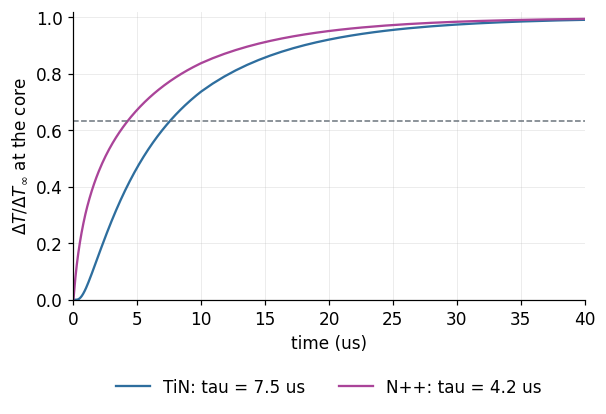

measured (Jacques 2019): TiN 5.6 us, N++ 2.2 us


In [7]:
# Turn-on step response of the core temperature (implicit time stepping, ~15 s per heater).
fig, ax = plt.subplots(figsize=(6, 3.4))
bench_tau = {}
for (name, prob), c in zip(bench.items(), (style.COLOR_STEEL, style.COLOR_PURPLE)):
    t, r = th.step_response(prob, 1e-8, 1e-3, to.point_reader(prob, 0.11), steps_per_decade=100)
    bench_tau[name] = th.time_constant(t, r) * 1e6
    ax.plot(t * 1e6, r, color=c, label=f"{name}: tau = {bench_tau[name]:.1f} us")
ax.axhline(1 - np.exp(-1), color=style.COLOR_REFERENCE, ls="--", lw=1)
ax.set_xlim(0, 40); ax.set_ylim(0, 1.02)
ax.set_xlabel("time (us)"); ax.set_ylabel(r"$\Delta T / \Delta T_\infty$ at the core")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)
plt.show()
print("measured (Jacques 2019): TiN 5.6 us, N++ 2.2 us")

The 2D model gives $\tau \approx 7.5$ µs (TiN) and 4.2 µs (N++). Flexcompute's reproduction of
the same 2D model reaches $1-1/e$ at about 7.5 and 4.3 µs (read from its plot), so the solver
agrees with an independent 2D solve. Both are **slower than the measured 5.6 and 2.2 µs**,
the N++ heater by a factor of two. The ordering (N++ faster) and the reason (its heat is
generated next to the core instead of 2 µm of oxide away) are reproduced; the absolute time
constants are not. Two known causes: a 2D cross-section has no heat flow along the heater,
and in 2D the substrate's thermal resistance keeps growing with depth (next cell), which
lengthens the slow tail of the response. Treat the time constants below as **relative**
values, good for comparing designs, and expect real devices to be faster.

### 6.3 Domain: how deep is the substrate?

The model keeps 6 µm of silicon under the BOX and holds its bottom at ambient temperature.
In a real chip the substrate is about 725 µm thick and spreads heat in three dimensions. In
2D, a deeper substrate keeps adding thermal resistance (heat conduction from a line source
in 2D has a logarithmically growing resistance), so the depth is a modeling choice that must
be tested, not assumed.

In [8]:
# P_pi and tau vs the substrate depth kept in the model (lateral half-width 150 um, wide enough
# that the adiabatic sides do not matter). ~20 s per case.
rows = []
for sub in (6, 20, 50, 150):
    st = {**STACK, "substrate_um": sub, "half_width_um": 150}
    for name, f in (("TiN", th.tin_heater_strip), ("N++", th.doped_si_heater_rib)):
        prob = f(wg_width_um=0.5, stack=st, h_max=max(0.5, sub / 40))
        rd = to.point_reader(prob, 0.11)
        dT_core = rd(th.solve_steady(prob, 1.0))
        t, r = th.step_response(prob, 1e-8, 1e-3, rd, steps_per_decade=60)
        rows.append((sub, name, WL_B * 1e-6 / (2 * DNDT_B * dT_core) * 1e3, th.time_constant(t, r) * 1e6))
print(f"{'substrate (um)':>15s} {'heater':>7s} {'P_pi (mW)':>10s} {'tau (us)':>9s}")
for sub, name, p, tau in rows:
    print(f"{sub:>15d} {name:>7s} {p:>10.2f} {tau:>9.2f}")

 substrate (um)  heater  P_pi (mW)  tau (us)
              6     TiN      23.85      7.57
              6     N++      25.19      4.25
             20     TiN      23.55      7.70
             20     N++      24.85      4.39
             50     TiN      23.31      7.83
             50     N++      24.58      4.51
            150     TiN      22.96      8.03
            150     N++      24.20      4.70


From 6 to 150 µm of substrate, $P_\pi$ falls by about 4 % and $\tau$ grows by 6-11 %. The
6 µm of Jacques' model is kept for every result below (so the benchmark and the design use
one model), and the spread is quoted as a model uncertainty. The quantity that is truly
sensitive to the substrate is far-field crosstalk (section 10).

### 6.4 Optical loss of the N++ heater

The doped strips absorb light where the mode's tail reaches them. With the doped-silicon
index Jacques used ($n = 3.072$, $\kappa = 0.137$ at 1.55 µm, i.e. $\alpha = 4\pi\kappa/\lambda
\approx 1.1\times10^4$ cm$^{-1}$), the perturbation formula with an imaginary $\Delta n$
gives the modal loss $\alpha_\mathrm{mode} = 2k_0\,\mathrm{Im}\,\Delta n_\mathrm{eff}$.

In [9]:
# Modal loss of the 500 nm rib from the N++ strips 0.8 um away (Jacques constants, 1.55 um),
# at two MPB resolutions: the absorbed fraction lives in the mode's exponential tail.
def doped_loss_db_per_cm(mode, wg_width_um, buffer_um, kappa, wl_um, doped_width=1.0, slab=0.09):
    # Overlap of the mode with the two N++ strips, and the modal loss from an imaginary index kappa there.
    X, Y = np.meshgrid(mode.x_um, mode.y_um)
    half = wg_width_um / 2
    dop = (np.abs(X) >= half + buffer_um) & (np.abs(X) <= half + buffer_um + doped_width) & (Y >= 0) & (Y <= slab)
    eps = np.where(mode.is_si, mode.n_si ** 2, mode.n_ox ** 2)
    den = np.sum(eps * mode.E2)
    gamma = np.sum((eps * mode.E2)[dop]) / den
    im_dneff = mode.n_g * np.sum((mode.n_si * kappa * mode.E2)[dop]) / den
    return 4.343 * 2 * (2 * np.pi / (wl_um * 1e-4)) * im_dneff, gamma

mode_params = {"wl0_um": 1.55, "wg_width_um": 0.5, "slab_um": 0.09, "slab_half_width_um": 3.0, "n_si": 3.476, "n_ox": 1.444}
for res in (64, 96):
    rib_b = xs.solve_mode(mode_params, resolution=res)
    loss, gamma = doped_loss_db_per_cm(rib_b, 0.5, 0.8, 0.137, 1.55)
    print(f"resolution {res}: overlap with N++ = {gamma:.2e}, loss = {loss:.3f} dB/cm   (Flexcompute's mode solve: 0.315 dB/cm)")

resolution 64: overlap with N++ = 6.27e-06, loss = 0.327 dB/cm   (Flexcompute's mode solve: 0.315 dB/cm)


resolution 96: overlap with N++ = 7.09e-06, loss = 0.370 dB/cm   (Flexcompute's mode solve: 0.315 dB/cm)


The loss agrees with the reference within 4-17 %, the spread coming from how the 90 nm slab
is resolved. An overlap of a few $10^{-6}$ is enough to cost 0.3 dB/cm: N++ silicon absorbs
$\sim5\times10^4$ dB/cm.

> **Checkpoint -- benchmark.** $P_\pi$ matches Jacques' calculation within 0.2 % and is
> 10 % above their measurement; the loss of the N++ heater matches the reference within
> ~15 %; the time constants are 1.3-2× slower than measured, a limitation of the 2D model
> shared by Jacques' own model. The design sections below use the same solver and model.

## 7. TiN heater at 1.31 µm

### 7.1 Temperature field and the two metrics

From here on the phase is computed with the **mode overlap** (section 1.3) on the 400 nm
strip at 1.31 µm, with Frey's $dn/dT$.

P_pi, mode overlap   : 16.83 mW
P_pi, point metric   : 18.71 mW   (ratio 1.112)


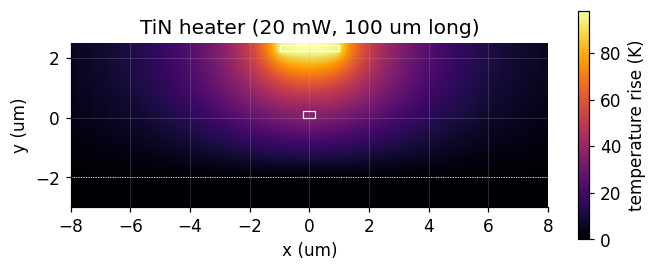

In [10]:
# Default TiN heater (2 um wide, 200 nm thick, 2 um above the Si) over the 400 nm strip.
p_tin = th.tin_heater_strip(wg_width_um=WG_WIDTH, stack=STACK)
T_tin = th.solve_steady(p_tin, 1.0)
d_mode = to.dneff_reader(p_tin, strip, DNDT_SI)(T_tin)
d_point = DNDT_SI * to.point_reader(p_tin, 0.11)(T_tin)
print(f"P_pi, mode overlap   : {WL0 * 1e-6 / (2 * d_mode) * 1e3:.2f} mW")
print(f"P_pi, point metric   : {WL0 * 1e-6 / (2 * d_point) * 1e3:.2f} mW   (ratio {d_mode / d_point:.3f})")

def plot_temperature(prob, T, p_mW, title, ax):
    # Temperature map for a given total heater power at the P_pi-relevant scale; outlines of the regions.
    scale = p_mW * 1e-3 / 100e-6                      # W/m for a 100 um heater (any L gives the same field per W/m)
    im = ax.pcolormesh(prob.x, prob.y, T * scale, cmap="inferno", shading="gouraud")
    for r in prob.rects:
        if r.name in ("substrate",):
            continue
        ax.add_patch(Rectangle((r.x0, r.y0), r.x1 - r.x0, r.y1 - r.y0, fill=False,
                               ec="white" if r.name != "trench" else "cyan", lw=0.8))
    ax.axhline(-STACK["box_um"], color="white", lw=0.6, ls=":")
    ax.set_xlim(-8, 8); ax.set_ylim(-3, STACK["clad_top_um"])
    ax.set_aspect("equal"); ax.set_xlabel("x (um)"); ax.set_ylabel("y (um)"); ax.set_title(title)
    return im

fig, ax = plt.subplots(figsize=(7, 3.0))
im = plot_temperature(p_tin, T_tin, 20.0, "TiN heater (20 mW, 100 um long)", ax)
fig.colorbar(im, ax=ax, label="temperature rise (K)", shrink=0.9)
plt.show()

The mode-overlap metric gives a $P_\pi$ about 10 % lower than the point metric: the factor
$(n_g/n_\mathrm{Si})\Gamma_\mathrm{Si}$ of section 4. The temperature map shows why the
heater is inefficient in the first place: the heat spreads sideways through the top oxide
and falls through the 2 µm BOX into the substrate over a width of ~8 µm, while the core is
only 0.4 µm wide.

At 1.31 µm the heater needs about 30 % less power than at 1.55 µm (16.8 vs 23.9 mW): $P_\pi
\propto\lambda/(dn/dT)$, and the overlap factor adds the rest.

### 7.2 Heater width

In [11]:
# TiN heater width: P_pi, tau (mode-weighted readout), P_pi*tau. ~15 s per width.
widths = [0.5, 1.0, 2.0, 3.0, 4.0]
tin_sweep = [to.evaluate(th.tin_heater_strip(wg_width_um=WG_WIDTH, heater_width_um=w, stack=STACK), strip, WL0, DNDT_SI,
                         steps_per_decade=60) for w in widths]
for w, r in zip(widths, tin_sweep):
    print(f"heater width {w:.1f} um: P_pi = {r.p_pi_mW:5.2f} mW, tau = {r.tau_us:4.2f} us, P_pi*tau = {r.p_pi_tau:5.0f} mW*us")

heater width 0.5 um: P_pi = 16.09 mW, tau = 7.14 us, P_pi*tau =   115 mW*us
heater width 1.0 um: P_pi = 16.25 mW, tau = 7.27 us, P_pi*tau =   118 mW*us
heater width 2.0 um: P_pi = 16.83 mW, tau = 7.57 us, P_pi*tau =   127 mW*us
heater width 3.0 um: P_pi = 17.69 mW, tau = 7.87 us, P_pi*tau =   139 mW*us
heater width 4.0 um: P_pi = 18.75 mW, tau = 8.17 us, P_pi*tau =   153 mW*us


A narrower heater concentrates the heat over the core, but the gain is small: from 2 µm to
0.5 µm, $P_\pi$ falls by only 4 %. The 2 µm of oxide between heater and core spreads the heat
over a few microns anyway. Narrow heaters cost more than they save: higher current density
(electromigration), higher resistance, tighter lithography. **The design keeps the 2 µm
width** of Jacques' fabricated heater.

## 8. Deep trenches

Etching the oxide away on both sides of the heater, down to the substrate, removes the
sideways heat path. The trenches here are 1.5 µm wide and filled with air (no convection
inside them); $d$ is the distance from the waveguide centre to the trench's inner edge.

no trench : P_pi = 16.83 mW, tau =  7.57 us, P_pi*tau =  127 mW*us
d = 2 um  : P_pi =  8.31 mW, tau = 10.78 us, P_pi*tau =   90 mW*us
d = 3 um  : P_pi = 11.56 mW, tau = 10.43 us, P_pi*tau =  121 mW*us
d = 5 um  : P_pi = 15.23 mW, tau =  8.81 us, P_pi*tau =  134 mW*us
d = 8 um  : P_pi = 16.62 mW, tau =  7.73 us, P_pi*tau =  128 mW*us


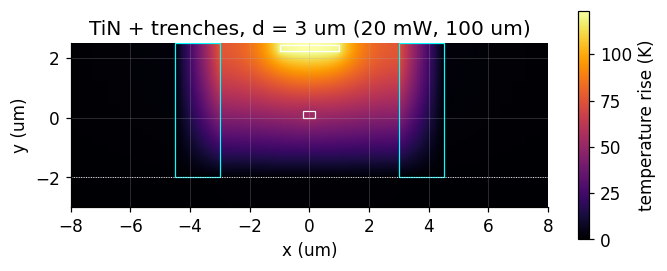

In [12]:
# TiN heater with air trenches through the top oxide and the BOX at |x| in [d, d + 1.5] um.
trench_d = [2.0, 3.0, 5.0, 8.0]
trench_sweep = [to.evaluate(th.tin_heater_strip(wg_width_um=WG_WIDTH, stack=STACK, trenches=[(d, d + 1.5), (-d - 1.5, -d)]),
                            strip, WL0, DNDT_SI, steps_per_decade=60) for d in trench_d]
base = tin_sweep[widths.index(2.0)]
print(f"no trench : P_pi = {base.p_pi_mW:5.2f} mW, tau = {base.tau_us:5.2f} us, P_pi*tau = {base.p_pi_tau:4.0f} mW*us")
for d, r in zip(trench_d, trench_sweep):
    print(f"d = {d:.0f} um  : P_pi = {r.p_pi_mW:5.2f} mW, tau = {r.tau_us:5.2f} us, P_pi*tau = {r.p_pi_tau:4.0f} mW*us")

p_tr = th.tin_heater_strip(wg_width_um=WG_WIDTH, stack=STACK, trenches=[(3.0, 4.5), (-4.5, -3.0)])
fig, ax = plt.subplots(figsize=(7, 3.0))
im = plot_temperature(p_tr, th.solve_steady(p_tr, 1.0), 20.0, "TiN + trenches, d = 3 um (20 mW, 100 um)", ax)
fig.colorbar(im, ax=ax, label="temperature rise (K)", shrink=0.9)
plt.show()

Trenches 2 µm from the core halve $P_\pi$ (16.8 to 8.3 mW). The heat is trapped in the
oxide column above the core and can leave only downward, through a narrower path; the price
is a slower heater ($\tau$ 7.6 to 11 µs), because the same heat capacity now drains through a
larger thermal resistance. $P_\pi\tau$ still improves at $d = 2$ µm. Trenches farther than
~5 µm do little. The trench must stay far enough from the waveguide that the mode does not
see it (at 2 µm from a 0.4 µm strip the mode's field is negligible); the design point uses
**$d = 3$ µm** as a margin against lithography and etch placement.

## 9. N++ doped-silicon heater

The alternative heater is the waveguide's own slab: two N++ strips in the 90 nm slab of a
rib waveguide, a distance $b$ from the rib, carry the current. The heat is generated in
silicon right next to the core, so it is fast; but the strips absorb light where the mode's
tail reaches them.

rib: n_eff = 2.6964, n_g = 3.8268 (waveguide), 4.0018 (with material dispersion)
N++ absorption estimate: 1.11e+04 /cm at 1.55 um -> 7.93e+03 /cm at 1.31 um


b = 0.4 um: P_pi = 15.96 mW, tau = 3.47 us, P_pi*tau =   55 mW*us, overlap 3.9e-04, loss ~ 14.5 dB/cm


b = 0.6 um: P_pi = 17.30 mW, tau = 3.82 us, P_pi*tau =   66 mW*us, overlap 2.2e-05, loss ~ 0.824 dB/cm


b = 0.8 um: P_pi = 18.67 mW, tau = 4.16 us, P_pi*tau =   78 mW*us, overlap 1.5e-06, loss ~ 0.057 dB/cm


b = 1.0 um: P_pi = 20.08 mW, tau = 4.50 us, P_pi*tau =   90 mW*us, overlap 8.5e-08, loss ~ 0.00318 dB/cm


b = 1.2 um: P_pi = 21.54 mW, tau = 4.82 us, P_pi*tau =  104 mW*us, overlap 8.3e-09, loss ~ 0.000311 dB/cm


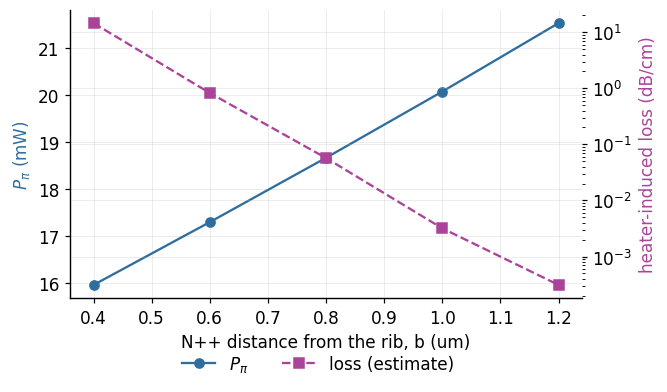

In [13]:
# Rib (400 nm, 90 nm slab) at 1.31 um, and the N++ heater vs its distance b from the rib.
P_RIB = {"wl0_um": WL0, "wg_width_um": WG_WIDTH, "slab_um": 0.09, "slab_half_width_um": 3.0}
rib = xs.solve_mode(P_RIB)
ng_disp_rib = xs.group_index_material_dispersive(P_RIB)
print(f"rib: n_eff = {rib.n_eff:.4f}, n_g = {rib.n_g:.4f} (waveguide), {ng_disp_rib:.4f} (with material dispersion)")

# N++ absorption at 1.31 um: Jacques' kappa at 1.55 um scaled by the Drude law alpha ~ lambda^2
# (an estimate; notebook 02 replaces it with the Nedeljkovic 2011 coefficients).
alpha_155 = 4 * np.pi * 0.137 / 1.55e-4                     # 1/cm
alpha_131 = alpha_155 * (WL0 / 1.55) ** 2
kappa_131 = alpha_131 * WL0 * 1e-4 / (4 * np.pi)
print(f"N++ absorption estimate: {alpha_155:.3g} /cm at 1.55 um -> {alpha_131:.3g} /cm at 1.31 um")

buffers = [0.4, 0.6, 0.8, 1.0, 1.2]
npp_sweep, npp_loss = [], []
for b in buffers:
    r = to.evaluate(th.doped_si_heater_rib(wg_width_um=WG_WIDTH, buffer_um=b, stack=STACK), rib, WL0, DNDT_SI, steps_per_decade=60)
    loss, gamma = doped_loss_db_per_cm(rib, WG_WIDTH, b, kappa_131, WL0)
    npp_sweep.append(r); npp_loss.append((loss, gamma))
    print(f"b = {b:.1f} um: P_pi = {r.p_pi_mW:5.2f} mW, tau = {r.tau_us:4.2f} us, P_pi*tau = {r.p_pi_tau:4.0f} mW*us, "
          f"overlap {gamma:.1e}, loss ~ {loss:.3g} dB/cm")

fig, ax1 = plt.subplots(figsize=(6, 3.4))
ax1.plot(buffers, [r.p_pi_mW for r in npp_sweep], "o-", color=style.COLOR_STEEL, label=r"$P_\pi$")
ax1.set_xlabel("N++ distance from the rib, b (um)"); ax1.set_ylabel(r"$P_\pi$ (mW)", color=style.COLOR_STEEL)
ax2 = ax1.twinx()
ax2.semilogy(buffers, [l for l, _ in npp_loss], "s--", color=style.COLOR_PURPLE, label="loss (estimate)")
ax2.set_ylabel("heater-induced loss (dB/cm)", color=style.COLOR_PURPLE)
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, frameon=False)
plt.show()

The trade-off is steep and one-sided. Moving the strips from 1.2 to 0.4 µm saves 26 % of
the power and makes the heater 30 % faster, while the absorption grows by more than four
orders of magnitude: the mode's tail in the slab decays exponentially. At $b = 0.8$ µm the
loss is about 0.06 dB/cm (0.002 dB for a 300 µm heater), at 0.4 µm it is about 15 dB/cm. **The design keeps $b = 0.8$ µm**, as Jacques did. Compared with the TiN heater, the
N++ heater has a similar $P_\pi$ (18.7 vs 16.8 mW in this model) and is ~1.8× faster, so its
$P_\pi\tau$ is about 40 % lower: the conclusion of Jacques et al. ("doped-Si heaters are the
most practical and efficient on standard SOI") is reproduced. It needs a rib waveguide and
N++ implants, which every foundry offers.

The loss numbers are estimates: the absorption of N++ silicon at 1.31 µm is scaled from
Jacques' 1.55 µm value with the Drude $\lambda^2$ law; notebook 02 brings in measured
free-carrier coefficients.

## 10. Thermal crosstalk

A heater also warms its neighbors. In an MZI mesh or a ring bank, that shifts the phase of
the waveguide next door. The crosstalk here is the phase on a neighbor waveguide at pitch $p$,
divided by the phase on the heated waveguide (both read with the same mode overlap; the
neighbor cores are part of the heat model).

no trench         : 5 um: 31.08 %  10 um:  5.78 %  15 um:  1.09 %  20 um:  0.22 %  30 um:  0.01 %  50 um:  0.00 %


trenches d = 3 um : 5 um:  2.85 %  10 um:  0.62 %  15 um:  0.14 %  20 um:  0.03 %  30 um:  0.00 %  50 um:  0.00 %


no trench, substrate   6 um: 5 um: 31.08 %  10 um:  5.78 %  15 um:  1.09 %  20 um:  0.22 %  30 um:  0.01 %  50 um:  0.00 %


no trench, substrate  50 um: 5 um: 32.56 %  10 um:  7.59 %  15 um:  2.75 %  20 um:  1.62 %  30 um:  0.99 %  50 um:  0.50 %


no trench, substrate 400 um: 5 um: 34.15 %  10 um:  9.76 %  15 um:  5.02 %  20 um:  3.90 %  30 um:  3.25 %  50 um:  2.66 %


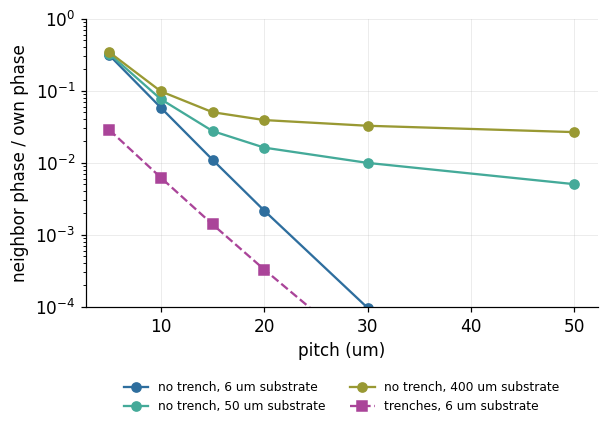

In [14]:
# Crosstalk vs pitch, TiN heater, without and with trenches (d = 3 um); then its sensitivity
# to the substrate depth kept in the 2D model.
pitches = [5, 10, 15, 20, 30, 50]
xt = {}
for label, tr in (("no trench", ()), ("trenches d = 3 um", [(3.0, 4.5), (-4.5, -3.0)])):
    prob = th.tin_heater_strip(wg_width_um=WG_WIDTH, neighbors_x_um=pitches, stack={**STACK, "half_width_um": 150}, trenches=tr)
    xt[label] = to.crosstalk(prob, strip, DNDT_SI, pitches)
    print(f"{label:18s}: " + "  ".join(f"{p} um: {100 * v:5.2f} %" for p, v in zip(pitches, xt[label])))

xt_sub = {}
for sub in (6, 50, 400):
    prob = th.tin_heater_strip(wg_width_um=WG_WIDTH, neighbors_x_um=pitches,
                               stack={**STACK, "half_width_um": max(150, 2 * sub), "substrate_um": sub}, h_max=max(0.5, sub / 40))
    xt_sub[sub] = to.crosstalk(prob, strip, DNDT_SI, pitches)
    print(f"no trench, substrate {sub:3d} um: " + "  ".join(f"{p} um: {100 * v:5.2f} %" for p, v in zip(pitches, xt_sub[sub])))

fig, ax = plt.subplots(figsize=(6, 3.4))
for (sub, v), c in zip(xt_sub.items(), (style.COLOR_STEEL, style.COLOR_TEAL, style.COLOR_OLIVE)):
    ax.semilogy(pitches, np.maximum(v, 1e-5), "o-", color=c, label=f"no trench, {sub} um substrate")
ax.semilogy(pitches, np.maximum(xt["trenches d = 3 um"], 1e-5), "s--", color=style.COLOR_PURPLE, label="trenches, 6 um substrate")
ax.set_xlabel("pitch (um)"); ax.set_ylabel("neighbor phase / own phase"); ax.set_ylim(1e-4, 1)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False, fontsize=8)
plt.show()

**Near the heater (5-10 µm) the 2D model is reliable**: the crosstalk is 31-34 % at 5 µm and
6-10 % at 10 µm whatever substrate depth is assumed, because there the heat travels through
the oxide. Trenches cut it by about ten times (3 % at 5 µm). **Far from the heater (≥15 µm)
the 2D model cannot give a number**: the crosstalk is carried by the heated substrate and
ranges from ~0 to ~5 % depending on the assumed depth. A real chip spreads that heat in 3D,
which the cross-section cannot describe; a 3D chip-scale model or a measurement is needed
there. Jacques et al. measured this crosstalk and found deep trenches the best standard-process
mitigation, consistent with the near-field result.

## 11. Frequency response of the selected designs

/home/yuma/meep-course/photonics-simulation-toolkit/src/pic_toolkit/active/si_xsection.py:197: ComplexWarning: Casting complex values to real discards the imaginary part
  return {"dneff": float(mode.n_g * (num_si + num_ox) / den),
/home/yuma/meep-course/photonics-simulation-toolkit/src/pic_toolkit/active/si_xsection.py:198: ComplexWarning: Casting complex values to real discards the imaginary part
  "si_share": float(num_si / (num_si + num_ox)) if (num_si + num_ox) else float("nan"),
/home/yuma/meep-course/photonics-simulation-toolkit/src/pic_toolkit/active/si_xsection.py:207: ComplexWarning: Casting complex values to real discards the imaginary part
  return {**perturbation_dneff(mode, dndT_si * dT, dndT_ox * dT), "dT_peak_in_si": float(dT[mode.is_si].max())}


tin        : P_pi = 16.83 mW, tau =  7.53 us, f_3dB =  13.4 kHz, 1/(2 pi tau) =  21.1 kHz
tin_trench : P_pi = 11.56 mW, tau = 10.38 us, f_3dB =  10.2 kHz, 1/(2 pi tau) =  15.3 kHz
n_doped    : P_pi = 18.67 mW, tau =  4.14 us, f_3dB =  20.1 kHz, 1/(2 pi tau) =  38.4 kHz


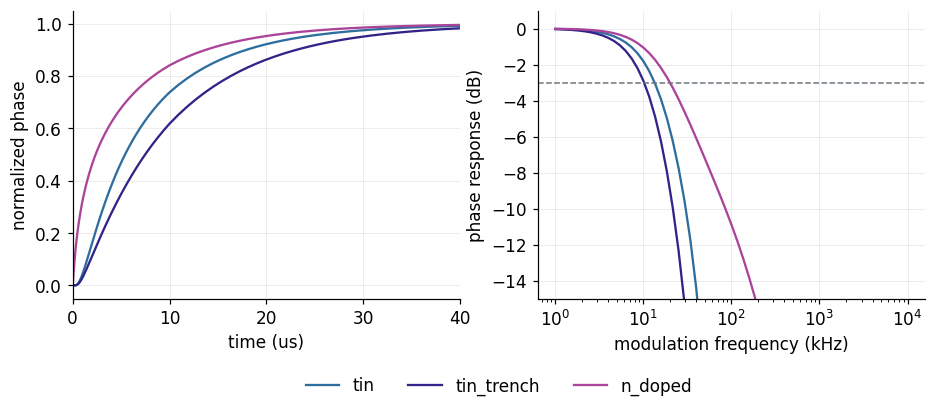

In [15]:
# The three variants saved in the design point: TiN (2 um), TiN with trenches at d = 3 um, N++ at b = 0.8 um.
variants = {
    "tin": (th.tin_heater_strip(wg_width_um=WG_WIDTH, stack=STACK), strip, ng_disp),
    "tin_trench": (th.tin_heater_strip(wg_width_um=WG_WIDTH, stack=STACK, trenches=[(3.0, 4.5), (-4.5, -3.0)]), strip, ng_disp),
    "n_doped": (th.doped_si_heater_rib(wg_width_um=WG_WIDTH, buffer_um=0.8, stack=STACK), rib, ng_disp_rib),
}
final = {k: to.evaluate(p, m, WL0, DNDT_SI, frequency=True) for k, (p, m, _) in variants.items()}

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
for (k, r), c in zip(final.items(), (style.COLOR_STEEL, style.COLOR_INDIGO, style.COLOR_PURPLE)):
    a1.plot(r.times_s * 1e6, r.step, color=c, label=k)
    a2.semilogx(r.freqs_hz / 1e3, 20 * np.log10(np.abs(r.H)), color=c, label=k)
    print(f"{k:11s}: P_pi = {r.p_pi_mW:5.2f} mW, tau = {r.tau_us:5.2f} us, f_3dB = {r.f3db_kHz:5.1f} kHz, "
          f"1/(2 pi tau) = {1e3 / (2 * np.pi * r.tau_us):5.1f} kHz")
a1.set_xlim(0, 40); a1.set_xlabel("time (us)"); a1.set_ylabel("normalized phase")
a2.axhline(-3, color=style.COLOR_REFERENCE, ls="--", lw=1)
a2.set_ylim(-15, 1); a2.set_xlabel("modulation frequency (kHz)"); a2.set_ylabel("phase response (dB)")
a2.legend(loc="upper center", bbox_to_anchor=(-0.1, -0.22), ncol=3, frameon=False)
plt.show()

The response is not a single pole. Heat reaches the core by diffusion, so the response falls
much faster than $-20$ dB/decade above its corner, and the $-3$ dB bandwidth is only
0.5-0.7 times the single-pole estimate $1/(2\pi\tau)$. Quote the bandwidth, not $\tau$, when a
control loop or a dithering scheme has to be designed around the heater. The N++ heater's
response falls more gently, because part of its heat is generated right next to the core.
Bandwidths of 10-20 kHz are typical of oxide-clad heaters away from the core; Harris et
al. measured 130 kHz for a doped heater inside the waveguide itself.

## 12. Tuning a ring resonator

With a heater covering the whole ring, the round-trip phase changes by $2\pi$ at $P = 2P_\pi$,
which moves the resonance by exactly one free spectral range. By section 1.2 this does not
depend on the ring's size, so the tuning **efficiency** in nm/mW is set by the FSR:

$$
\frac{d\lambda}{dP} = \frac{\mathrm{FSR}}{2P_\pi}, \qquad \mathrm{FSR} = \frac{\lambda^2}{n_g L}.
$$

The FSR uses the group index **with** material dispersion. The straight-waveguide cross-section
stands in for the bent one, and the heater is assumed to cover the whole circumference
(real ring heaters leave a gap for the bus coupler, which raises the power by the uncovered
fraction).

In [16]:
for k in ("tin", "n_doped"):
    ng = variants[k][2]
    for R in (5.0, 10.0, 20.0):
        rt = to.ring_tuning(final[k].p_pi_mW, R, WL0, ng)
        print(f"{k:8s} R = {R:4.0f} um: FSR = {rt['fsr_nm']:5.2f} nm, power for one FSR = {rt['p_fsr_mW']:5.1f} mW, "
              f"{rt['nm_per_mW']:.3f} nm/mW")

tin      R =    5 um: FSR = 12.61 nm, power for one FSR =  33.7 mW, 0.375 nm/mW
tin      R =   10 um: FSR =  6.31 nm, power for one FSR =  33.7 mW, 0.187 nm/mW
tin      R =   20 um: FSR =  3.15 nm, power for one FSR =  33.7 mW, 0.094 nm/mW
n_doped  R =    5 um: FSR = 13.65 nm, power for one FSR =  37.3 mW, 0.366 nm/mW
n_doped  R =   10 um: FSR =  6.83 nm, power for one FSR =  37.3 mW, 0.183 nm/mW
n_doped  R =   20 um: FSR =  3.41 nm, power for one FSR =  37.3 mW, 0.091 nm/mW


Two design consequences. First, a small ring has a large FSR and therefore a high tuning
efficiency in nm/mW, but the power needed to reach **any** point of its FSR is the same
~34 mW for every radius. Second, what matters in a ring bank is the power needed to cover
the **fabrication-induced** resonance spread, which is a fixed number of nm (a few nm for
width variations of a few nm in a 220 nm strip); a small ring needs less power to cover it.
This is one reason transmitter rings are small (5-10 µm radius).

## 13. Design point, SAX model and layout

> **STOP -- consequential step.** The next cell writes
> `si_active/data/design_points/thermo_optic_phase_shifter.yaml`, which the SAX model
> `pic_toolkit.models.thermo_optic_phase_shifter` reads. Check the numbers above first.

In [17]:
# Design point: one record per heater variant. Phases and P_pi are per the mode overlap at 1.31 um.
def variant_record(key, geometry, loss_db_per_cm, xt_row):
    r = final[key]
    prob, mode, ng = variants[key]
    return {
        "geometry": geometry,
        "optical": {"wg_width_um": WG_WIDTH, "slab_um": 0.09 if key == "n_doped" else 0.0, "n_eff": round(mode.n_eff, 5),
                    "n_g_waveguide": round(mode.n_g, 4), "n_g_dispersive": round(ng, 4), "mpb_resolution": mode.resolution},
        "p_pi_mW": round(r.p_pi_mW, 3), "dneff_per_W_per_m": float(r.dneff_per_W_per_m),
        "tau_us": round(r.tau_us, 3), "f3db_kHz": round(r.f3db_kHz, 2), "p_pi_tau_mW_us": round(r.p_pi_tau, 1),
        "loss_db_per_cm": float(loss_db_per_cm),
        "crosstalk_5um": None if xt_row is None else round(float(xt_row[0]), 4),
        "crosstalk_10um": None if xt_row is None else round(float(xt_row[1]), 4),
    }

record = {
    "component": "thermo_optic_phase_shifter",
    "wl0_um": WL0,
    "stack": STACK,
    "materials": {"n_si": round(strip.n_si, 5), "n_sio2": round(strip.n_ox, 5), "dndT_si_per_K": DNDT_SI,
                  "dndT_sio2_per_K": xs.SIO2_DNDT, "thermal": th.THERMAL_MATERIALS,
                  "sources": "Frey 2006 (Si n, dn/dT), Malitson 1965 (SiO2), Jacques 2019 Table 3 (thermal)"},
    "variants": {
        "tin": variant_record("tin", {"heater": "TiN", "heater_width_um": 2.0, "heater_thickness_um": 0.2,
                                      "heater_gap_above_si_um": 2.0}, 0.0, xt["no trench"]),
        "tin_trench": variant_record("tin_trench", {"heater": "TiN", "heater_width_um": 2.0, "heater_thickness_um": 0.2,
                                                    "heater_gap_above_si_um": 2.0, "trench_inner_edge_um": 3.0,
                                                    "trench_width_um": 1.5, "trench_depth": "top oxide + BOX, to the substrate"},
                                     0.0, xt["trenches d = 3 um"]),
        "n_doped": variant_record("n_doped", {"heater": "N++ Si in the 90 nm slab", "buffer_um": 0.8, "doped_width_um": 1.0},
                                  npp_loss[buffers.index(0.8)][0], None),
    },
    "benchmark": {"reference": "Jacques et al., Opt. Express 27, 10456 (2019)", "wl_um": WL_B, "dndT": DNDT_B,
                  "p_pi_mW": {k: round(v, 2) for k, v in bench_ppi.items()}, "p_pi_paper_calc_mW": paper_calc,
                  "p_pi_paper_meas_mW": paper_meas, "tau_us": {k: round(v, 2) for k, v in bench_tau.items()},
                  "tau_paper_meas_us": {"TiN": 5.6, "N++": 2.2}},
    "model_assumptions": [
        "2D cross-section, uniform along the heater (heater length >> cross-section)",
        "substrate 6 um deep in the model with an isothermal bottom; 6 -> 150 um changes P_pi by ~-4 % and tau by ~+10 %",
        "time constants 1.3-2x slower than measured in the benchmark: use them as relative values",
        "crosstalk beyond ~15 um is set by 3D substrate spreading and is not predicted",
        "N++ loss: Drude lambda^2 scaling of Jacques' 1.55 um absorption (estimate)",
        "optics non-dispersive at wl0 except n_g_dispersive",
    ],
    "provenance": {"notebook": "si_active/notebooks/01_thermo_optic_phase_shifter.ipynb",
                   "date": time.strftime("%Y-%m-%d"), "solver": "pic_toolkit.active.thermal (FV) + MPB"},
}
dp_path = DATA / "design_points" / "thermo_optic_phase_shifter.yaml"
design_points.save_design_point(dp_path, record)
print("saved", dp_path)
for k, v in record["variants"].items():
    print(f"  {k:11s}: P_pi {v['p_pi_mW']} mW, tau {v['tau_us']} us, f3dB {v['f3db_kHz']} kHz, loss {v['loss_db_per_cm']:.3g} dB/cm")

saved ../data/design_points/thermo_optic_phase_shifter.yaml
  tin        : P_pi 16.833 mW, tau 7.534 us, f3dB 13.44 kHz, loss 0 dB/cm
  tin_trench : P_pi 11.56 mW, tau 10.38 us, f3dB 10.21 kHz, loss 0 dB/cm
  n_doped    : P_pi 18.67 mW, tau 4.143 us, f3dB 20.07 kHz, loss 0.057 dB/cm


### 13.1 SAX model, in a process without Meep

The SAX model must work where Meep was never imported (CLAUDE.md §8). It is run in a fresh
Python process: an MZI-style check drives the heater to $P_\pi$ and confirms the phase moves
by $\pi$.

In [18]:
check = r'''
import sys, numpy as np
from pic_toolkit.models import thermo_optic_phase_shifter as tops
assert "meep" not in sys.modules
for v in ("tin", "tin_trench", "n_doped"):
    p_pi = tops.load(v)["p_pi_mW"]
    s0 = tops.thermo_optic_phase_shifter(wl=1.31, power_mW=0.0, length_um=200, variant=v)[("o1", "o2")]
    s1 = tops.thermo_optic_phase_shifter(wl=1.31, power_mW=p_pi, length_um=200, variant=v)[("o1", "o2")]
    print(v, "phase change at P_pi / pi =", round(float(np.angle(s1 / s0)) / np.pi, 6), " |S21| =", round(float(abs(s1)), 6))
print("meep imported:", "meep" in sys.modules)
'''
print(subprocess.run([sys.executable, "-c", check], capture_output=True, text=True).stdout)

tin phase change at P_pi / pi = 1.0  |S21| = 1.0
tin_trench phase change at P_pi / pi = 1.0  |S21| = 1.0
n_doped phase change at P_pi / pi = 1.0  |S21| = 0.999869
meep imported: False



### 13.2 Layout

The layouts come from gdsfactory's generic PDK cells, set to this design's widths: a
320 µm TiN-heater straight over the 400 nm strip, the N++ rib heater (strips 1 µm wide,
0.8 µm from the rib), and a 10 µm-radius ring with a heater. The trenches are not part of
the generic PDK's heater cell and are left to the foundry's trench layer.

tops_tin_320um      :   351.8 x  11.0 um -> ../data/gds/tops_tin_320um.gds
tops_n_doped_320um  :   320.0 x  50.0 um -> ../data/gds/tops_n_doped_320um.gds
ring_r10_tin_heater :    27.0 x  23.6 um -> ../data/gds/ring_r10_tin_heater.gds


/home/yuma/miniconda3/envs/mp/lib/python3.10/site-packages/gdsfactory/pdk.py:439: UserWarning: {'radius': 10} are ignored for cross_section 'xs_d9e914be'
  warnings.warn(


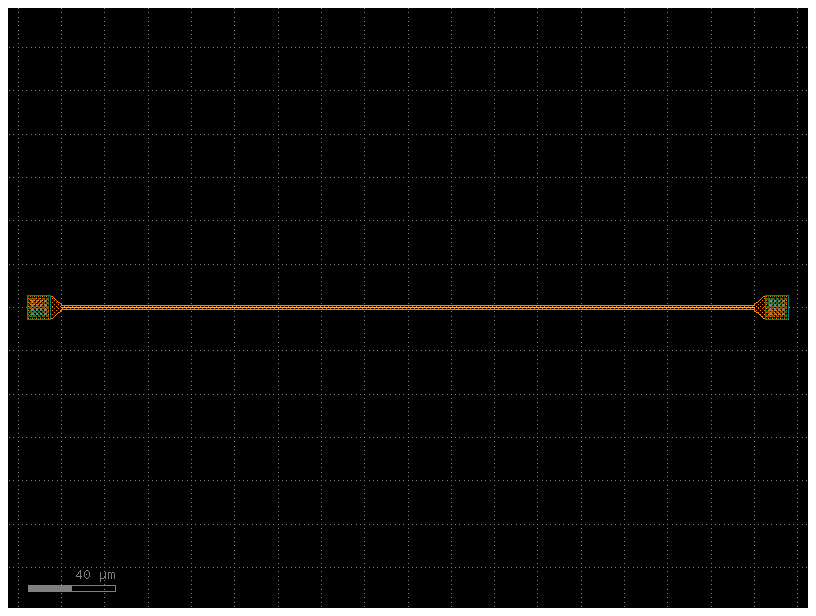

In [19]:
import gdsfactory as gf

xs_wg = gf.cross_section.strip(width=WG_WIDTH)
xs_heater = gf.cross_section.strip_heater_metal(width=WG_WIDTH, heater_width=2.0)
layouts = {
    "tops_tin_320um": gf.components.straight_heater_metal(length=320, cross_section=xs_wg, cross_section_waveguide_heater=xs_heater),
    "tops_n_doped_320um": gf.components.straight_heater_doped_rib(length=320, width=WG_WIDTH, heater_gap=0.8, heater_width=1.0),
    "ring_r10_tin_heater": gf.components.ring_single_heater(radius=10, gap=0.2, cross_section=xs_wg, cross_section_waveguide_heater=xs_heater),
}
for name, c in layouts.items():
    path = DATA / "gds" / f"{name}.gds"
    c.write_gds(path)
    print(f"{name:20s}: {c.xsize:7.1f} x {c.ysize:5.1f} um -> {path}")
layouts["tops_tin_320um"].plot()

## 14. Summary

| | TiN, 2 µm | TiN + trenches ($d$ = 3 µm) | N++ ($b$ = 0.8 µm) |
|---|---|---|---|
| Waveguide | 400 × 220 nm strip | same | 400 nm rib, 90 nm slab |
| $P_\pi$ at 1.31 µm | 16.8 mW | 11.6 mW | 18.7 mW |
| $\tau$ (2D model, relative) | 7.5 µs | 10.4 µs | 4.1 µs |
| $f_\mathrm{3dB}$ (2D model) | 13 kHz | 10 kHz | 20 kHz |
| Heater-induced loss | none modeled | none modeled | ~0.06 dB/cm (estimate) |
| Crosstalk at 5 / 10 µm pitch | 31 % / 6 % | 3 % / 0.6 % | -- |
| Power for one ring FSR | 34 mW | 23 mW | 37 mW |

(From the printouts above; the design point holds the unrounded values.)

**What the benchmark establishes.** The heat solver reproduces an exact solution to round-off,
Jacques et al.'s calculated $P_\pi$ within 0.2 % and their measured $P_\pi$ within 10 %
(the same offset as their own model), and the N++ heater's optical loss within ~15 %.

**Design rules from the physics.**
- $P_\pi$ does not depend on the heater length; length sets resistance, voltage and current density.
- The phase follows the mode-weighted index, which a strip waveguide **amplifies** by
  $(n_g/n_\mathrm{Si})\Gamma_\mathrm{Si}\approx1.1$ over the bulk $dn/dT$.
- Heater width barely matters once it is ~2 µm away from the core; trenches and heater
  placement do.
- The N++ heater wins on $P_\pi\tau$; its distance to the rib is set by an exponential loss
  trade-off, not by power.
- A ring needs $2P_\pi$ for one FSR, whatever its radius.

**Limits of this model.**
- 2D cross-section: no heat flow along the heater, ends or bends; real time constants are
  shorter than modeled (1.3-2× in the benchmark).
- Far-field crosstalk (≥15 µm) and absolute substrate heating need a 3D chip model.
- Undercut (released) heaters are not modeled: they need the 3D support structure.
- Electrical side not modeled: heater resistance, voltage, current density and
  electromigration limits of TiN.
- N++ absorption at 1.31 µm is a Drude-scaled estimate; temperature-dependent conductivity
  and $dn/dT$ (both change by a few % over 50 K) are neglected.